DBSCAN (Density-Based Spatial Clustering of Applications with Noise) — это алгоритм
кластеризации, который группирует близкие друг к другу точки в кластеры и считает точки,
которые не принадлежат ни одному кластеру, выбросами или шумом. В отличие от
алгоритмов, таких как K-means, DBSCAN не требует заранее заданного количества
кластеров и может работать с кластерами произвольной формы.
	 Основные понятия DBSCAN:
1. Эпсилон (ε) — радиус, в пределах которого точки могут быть соседями.
2. Минимальное количество соседей (minPts) — минимальное количество точек, которые
должны быть в пределах радиуса эпсилона, чтобы точку можно было считать "срединной"
точкой кластера (не шумом).
3. Ядровая точка — точка, у которой в радиусе эпсилон есть не менее minPts точек
(включая саму себя).
4. Шумная точка — точка, не являющаяся ядровой точкой и не имеющая достаточного
количества соседей, чтобы быть частью какого-либо кластера.
5. Граничная точка — точка, которая находится в пределах радиуса эпсилона от ядровой
точки, но сама не имеет достаточно соседей для того, чтобы быть ядровой.

In [1]:
import numpy as np
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt

In [2]:
X = np.array([[0, 0], [0.5, 0.5], [1, 0], [3, 3], [3.5, 3.5], [10, 10]])

In [3]:
# Применяем DBSCAN
db = DBSCAN(eps=1.0, min_samples=3)
db.fit(X)

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",1.0
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",3
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
"components_ components_: ndarray of shape (n_core_samples, n_features)Copy of each core sample found by training.","ndarray[float64](3, 2)","[[0. ,0. ], [0.5,0.5], [1. ,0. ]]"
"core_sample_indices_ core_sample_indices_: ndarray of shape (n_core_samples,)Indices of core samples.","ndarray[int64](3,)","[0,1,2]"


In [4]:
# Получаем метки кластеров (-1 — шум)
labels = db.labels_

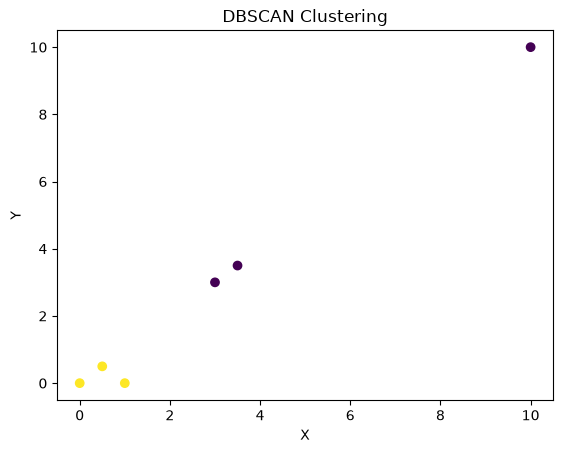

In [6]:
# Визуализация
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis')
plt.title('DBSCAN Clustering')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

Применение кластеризации для анализа данных
	 Представь себе, что ты работаешь в интернет-магазине, и у тебя есть огромная база
данных о покупателях: их покупки, частота заказов, средняя сумма чека, возраст,
предпочтения. Тебе нужно понять, какие группы клиентов существуют, чтобы предложить
им персонализированные акции или рекомендации. Но как их разделить? Здесь на помощь
приходит кластеризация.
Допустим, у тебя есть три типа покупателей:
1. Те, кто часто заказывает небольшие и недорогие товары. Они заходят в магазин почти
каждый день, но не тратят много денег за раз.
2. Те, кто делает редкие, но крупные покупки — раз в месяц или даже реже, но сразу на
большую сумму.
3. Те, кто делает покупки нерегулярно, без четкой системы, но в среднем их заказы
довольно стабильны по размеру.
	 Если пытаться вручную разделить клиентов, придется просмотреть тысячи записей
и гадать, кто относится к какой группе. Но DBSCAN автоматически выявит эти кластеры,
анализируя плотность данных. Он сгруппирует людей, поведение которых похоже, и
выделит тех, кто не вписывается ни в одну из групп (например, новых покупателей, у
которых еще мало данных, или аномальных клиентов, делающих единичные большие
покупки).
	 Теперь ты можешь использовать результаты. Первой группе можно предложить
подписку на доставку, ведь они часто покупают. Второй — скидку на большие заказы.
Третьей — напомнить о себе и предложить что-то, основываясь на их предыдущих
покупках.
	 Кластеризация применяется не только в маркетинге. В медицине она помогает
находить группы пациентов с похожими симптомами, в кибербезопасности — выявлять
подозрительную активность в сети, а в науке — анализировать геоданные, находя
аномалии в распределении землетрясений или погодных условий. Алгоритм DBSCAN
особенно удобен, когда кластеры имеют сложную форму и заранее неизвестно их
количество.

Пример задачи: Кластеризация клиентов интернет-магазина
	 Допустим, у нас есть база данных о клиентах интернет-магазина с такими
характеристиками:
- Частота покупок (сколько раз в месяц клиент делает заказ)
- Средняя сумма заказа

а цель — сгруппировать клиентов с похожим поведением с помощью DBSCAN и
понять, какие группы существуют.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

In [8]:
# Генерация случайных данных: (Частота покупок, Средняя сумма заказа)
data = np.array([
 [2, 20], [3, 25], [2, 22], [3, 28], [4, 26], # Группа 1 (часто, но дешево)
 [10, 100], [11, 110], [12, 105], [10, 95], [11, 98], # Группа 2 (редко, но дорого)
 [5, 50], [6, 55], [7, 53], [6, 52], [5, 48], # Группа 3 (средние траты)
 [15, 200] # Аномальный клиент (шум)
])

In [9]:
# Масштабируем данные для лучшей работы алгоритма
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

In [10]:
# Применяем DBSCAN
dbscan = DBSCAN(eps=0.8, min_samples=3) # Параметры нужно подбирать экспериментально
labels = dbscan.fit_predict(data_scaled)

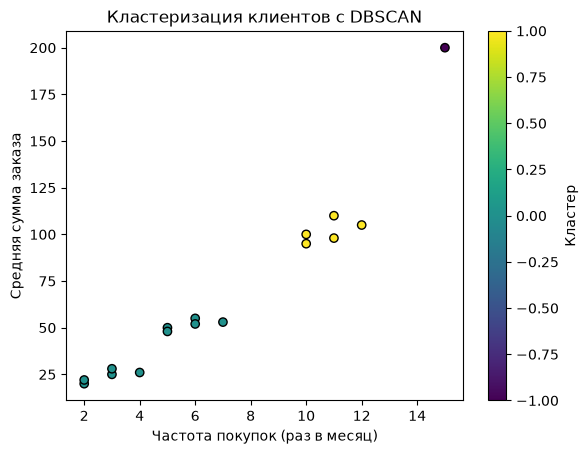

In [11]:
# Визуализация результатов
plt.scatter(data[:, 0], data[:, 1], c=labels, cmap='viridis', edgecolors='k')
plt.xlabel("Частота покупок (раз в месяц)")
plt.ylabel("Средняя сумма заказа")
plt.title("Кластеризация клиентов с DBSCAN")
plt.colorbar(label="Кластер")
plt.show()

Разбор работы кода.
	 Мы создали три естественные группы клиентов:
 - Одни покупают часто, но тратят мало.
 - Другие делают редкие, но дорогие заказы.
 - Третьи находятся посередине.
 - Также добавили одного аномального клиента, который сильно выбивается.
 Стандартизировали данные, чтобы алгоритм работал корректно, так как DBSCAN
чувствителен к масштабу.
	 Применили DBSCAN, указав `eps=0.8` (радиус соседства) и `min_samples=3` (чтобы
точку считали кластером, рядом должно быть минимум 3 других точки).
	 Результаты визуализированы, где точки одного цвета принадлежат одному
кластеру, а выброс (аномалия) отмечен отдельно.